# Semana 0 · Python esencial para el curso

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/prof-rodolfo-medina/modelizacion-derivados-carteras/blob/main/sesiones/semana-00/semana-00-python-esencial.ipynb)

**Autoestudio previo al 02/11/2026 · 60–90 minutos · no evaluable**

Este cuaderno es para quien tiene **poca o ninguna experiencia programando**. Cubre *solo* lo que se usa en el curso,
y cada concepto se ilustra con un ejemplo de los apuntes. Al terminar sabrás:

1. Usar Python como calculadora financiera (interés continuo, exponenciales, logaritmos).
2. Trabajar con **vectores de NumPy**, la herramienta central del curso (pagos de opciones, simulaciones).
3. Escribir **funciones** propias.
4. Hacer **gráficas** de beneficios/pérdidas con Matplotlib.
5. Leer datos de un **CSV** con pandas y calcular rendimientos.
6. Operar con **matrices** (carteras, Temas 8–10).
7. Generar **números aleatorios** (movimiento browniano, Tema 5).
8. **Leer un mensaje de error** sin pánico.

> Complementa este cuaderno con la [Guía para principiantes](../../docs/guia-principiantes.md) y la
> [chuleta de Python](../../docs/chuleta-python.md). Las dudas se plantean en el foro
> «Pregúntale a tu profesor» del aula virtual o en la sesión síncrona.

## 0. Cómo se usa un cuaderno

- Un cuaderno tiene **celdas de texto** (como esta) y **celdas de código** (fondo gris).
- Para ejecutar una celda de código: haz clic en ella y pulsa **Shift + Enter**.
- El resultado aparece debajo de la celda. Las celdas se ejecutan **en el orden en que tú las ejecutas**,
  no en el orden en que aparecen: si algo falla con un `NameError`, probablemente te saltaste una celda.
- Si te pierdes: menú **Entorno de ejecución → Reiniciar y ejecutar todo** (Colab) o
  **Kernel → Restart & Run All** (Jupyter/VS Code).
- Las líneas que empiezan por `#` son **comentarios**: Python las ignora; sirven para explicar el código.

Ejecuta la siguiente celda. Carga las tres librerías que usaremos en todo el curso y define una función
`comprobar` para autoevaluar los ejercicios.

In [1]:
# Librerías del curso (vienen instaladas en Colab)
import numpy as np                 # cálculo numérico: vectores y matrices
import pandas as pd                # tablas de datos (como una hoja de cálculo)
import matplotlib.pyplot as plt    # gráficas

def comprobar(respuesta, esperado, tol=1e-6):
    """Compara tu respuesta con el valor esperado e imprime el resultado."""
    if respuesta is None:
        print("⏳ Aún sin responder: escribe tu código en lugar de None y vuelve a ejecutar la celda.")
        return
    try:
        ok = np.allclose(np.asarray(respuesta, dtype=float), np.asarray(esperado, dtype=float), atol=tol)
    except Exception:
        ok = False
    print("✅ ¡Correcto!" if ok else "❌ Todavía no. Revisa tu código o consulta la solución al final.")

print("Todo listo. NumPy", np.__version__, "· pandas", pd.__version__)

Todo listo. NumPy 2.5.3 · pandas 3.0.5


## 1. Python como calculadora financiera

Operaciones básicas: `+ - * /`, potencia `**`. Para $e^x$ y $\ln x$ usamos `np.exp` y `np.log`.

Ejemplo (Tema 3): con interés compuesto continuo a tasa $r$, una cantidad $S_0$ vale $S_0 e^{r\tau}$
al cabo de $\tau$ años.

In [2]:
S0 = 100        # inversión inicial (€)
r = 0.05        # tasa libre de riesgo anual
tau = 1         # años

valor_final = S0 * np.exp(r * tau)       # capitalizar
print(valor_final)
print(f"Valor final: {valor_final:.2f} €")   # f-string: muestra 2 decimales

105.12710963760242
Valor final: 105.13 €


**Variables:** `S0 = 100` guarda el valor 100 con el nombre `S0`. Los nombres distinguen mayúsculas
(`S0` ≠ `s0`) y no pueden tener espacios ni empezar por número.

### ✏️ Ejercicio 1
Calcula el **valor actual** de 100 € que recibirás dentro de 2 años, con $r = 0.05$ continuo:
$100\,e^{-r\cdot 2}$. Guarda el resultado en `valor_actual`.

In [3]:
valor_actual = None   # ← sustituye None por tu cálculo

comprobar(valor_actual, 90.48374180359595)

⏳ Aún sin responder: escribe tu código en lugar de None y vuelve a ejecutar la celda.


## 2. Vectores con NumPy: muchos cálculos de una vez

En el curso evaluamos fórmulas para **muchos valores a la vez**: por ejemplo, el pago de una opción para todos los
precios posibles del subyacente $S_T$. Un **array** de NumPy es una lista de números con la que se opera
elemento a elemento, sin bucles.

In [4]:
ST = np.array([80, 90, 100, 110, 120])   # cinco precios posibles al vencimiento
print(ST)
print(ST - 100)        # se resta 100 a cada elemento
print(ST * 2)          # se multiplica cada elemento
print(ST.mean(), ST.min(), ST.max(), len(ST))

[ 80  90 100 110 120]
[-20 -10   0  10  20]
[160 180 200 220 240]
100.0 80 120 5


Dos funciones que usarás constantemente:

- `np.linspace(a, b, n)`: `n` valores equiespaciados entre `a` y `b` (para el eje horizontal de una gráfica).
- `np.maximum(x, 0)`: compara **elemento a elemento** con 0 y se queda con el mayor. Es justo $(x)^+$.

Ejemplo (Tema 1): el pago de una **call** es $(S_T - K)^+ = \max\{S_T - K, 0\}$.

In [5]:
K = 100
pago_call = np.maximum(ST - K, 0)
print("S_T      :", ST)
print("pago call:", pago_call)

malla = np.linspace(0, 200, 5)    # 0, 50, 100, 150, 200
print(malla)

S_T      : [ 80  90 100 110 120]
pago call: [ 0  0  0 10 20]
[  0.  50. 100. 150. 200.]


> ⚠️ **Error típico:** usar `max(...)` (de Python) en lugar de `np.maximum(...)`. `max` devuelve un solo número
> o falla con arrays; `np.maximum` trabaja elemento a elemento.

### ✏️ Ejercicio 2
Calcula el **pago de una put** $(K - S_T)^+$ con $K = 100$ para `ST = np.array([80, 100, 120])`.

In [6]:
ST2 = np.array([80, 100, 120])
pago_put = None   # ← tu código

comprobar(pago_put, [20, 0, 0])

⏳ Aún sin responder: escribe tu código en lugar de None y vuelve a ejecutar la celda.


## 3. Funciones: escribir una fórmula una vez y reutilizarla

Una **función** recibe datos (argumentos), hace un cálculo y devuelve (`return`) un resultado. La sangría
(4 espacios) indica qué líneas pertenecen a la función.

In [7]:
def bp_call_larga(ST, K, C):
    """Beneficio/pérdida de una call larga a vencimiento: (S_T - K)^+ - C."""
    pago = np.maximum(ST - K, 0)
    return pago - C

# La usamos con distintos datos sin reescribir la fórmula
print(bp_call_larga(np.array([90, 100, 110, 120]), K=100, C=5))
print(bp_call_larga(np.array([90, 100, 110, 120]), K=105, C=3))

[-5 -5  5 15]
[-3 -3  2 12]


### ✏️ Ejercicio 3
Completa la función `bp_put_larga(ST, K, P)` que devuelva $(K - S_T)^+ - P$ (Tema 1, expresión (1)).

In [8]:
def bp_put_larga(ST, K, P):
    """Beneficio/pérdida de una put larga a vencimiento."""
    return None   # ← sustituye None por la fórmula

comprobar(bp_put_larga(np.array([80, 100, 120]), K=100, P=4), [16, -4, -4])

⏳ Aún sin responder: escribe tu código en lugar de None y vuelve a ejecutar la celda.


## 4. Gráficas con Matplotlib

Una gráfica de beneficios/pérdidas se construye en cinco pasos: malla de $S_T$ → cálculo → `plt.plot` →
detalles (ejes, título, línea del cero, leyenda) → mostrar.

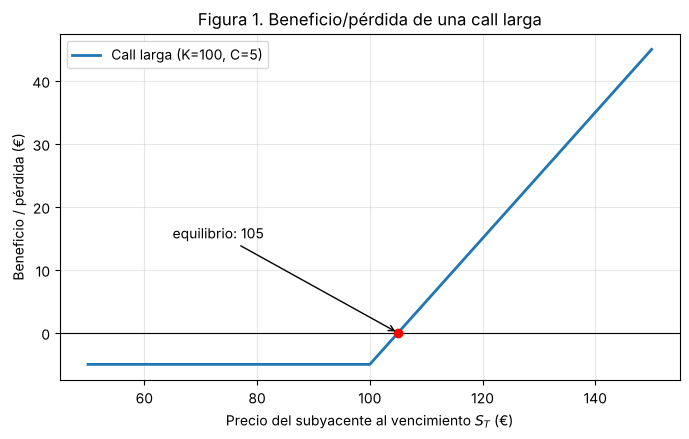

In [9]:
ST = np.linspace(50, 150, 201)           # 201 puntos entre 50 y 150
bp = bp_call_larga(ST, K=100, C=5)

plt.figure(figsize=(8, 4.5))
plt.plot(ST, bp, linewidth=2, label="Call larga (K=100, C=5)")
plt.axhline(0, color="black", linewidth=0.8)             # línea del cero
plt.plot(105, 0, "o", color="red")                         # marcar un punto: (x, y)
plt.annotate("equilibrio: 105", (105, 0), xytext=(65, 15),
             arrowprops=dict(arrowstyle="->"))             # texto con flecha
plt.xlabel("Precio del subyacente al vencimiento $S_T$ (€)")
plt.ylabel("Beneficio / pérdida (€)")
plt.title("Figura 1. Beneficio/pérdida de una call larga")
plt.grid(alpha=0.3)
plt.legend()
plt.show()
# Para guardar la figura en un archivo (para el informe), antes de plt.show():
# plt.savefig("figura1.png", dpi=200, bbox_inches="tight")

### ✏️ Ejercicio 4 (sin autocorrección)
Grafica el beneficio/pérdida de una **call corta** con $K = 100$ y $C = 6$: $C - (S_T - K)^+$.
Pon título, nombres de ejes, la línea del cero y marca el punto de equilibrio ($S_T = K + C$).
Compara tu gráfica con la Figura 2 del Tema 1.

In [10]:
# Tu código aquí (puedes copiar la celda anterior y adaptarla)

## 5. Datos con pandas: leer un CSV y calcular rendimientos

Un **DataFrame** de pandas es una tabla: filas (fechas o índices) y columnas (variables). Cargamos las
28 cotizaciones del ejemplo del Tema 6, incluidas en la carpeta `datos/` del repositorio.

In [11]:
from pathlib import Path

nombre = "tema6_ibex_28dias.csv"
url = "https://raw.githubusercontent.com/prof-rodolfo-medina/modelizacion-derivados-carteras/main/datos/" + nombre
# Si tienes el repositorio en tu ordenador se usa la copia local; si no (Colab), se descarga de GitHub
locales = [p for p in [Path("datos") / nombre, Path("../../datos") / nombre] if p.exists()]
datos = pd.read_csv(locales[0] if locales else url)

print(datos.shape)        # (filas, columnas)
datos.head()              # primeras 5 filas

(28, 2)


,t,S
0,0,24.38
1,1,24.23
2,2,24.26
3,3,24.32
4,4,24.89


In [12]:
S = datos["S"]            # una columna (Serie de pandas)
print(S.describe())       # resumen estadístico

count    28.000000
mean     24.955000
std       0.771662
min      23.550000
25%      24.305000
50%      25.010000
75%      25.500000
max      26.250000
Name: S, dtype: float64


**Log-rendimientos** (Tema 6): $U_i = \ln(S_i / S_{i-1})$. `S.shift(1)` desplaza la serie una posición,
así `S / S.shift(1)` divide cada precio entre el anterior. El primer valor queda vacío (`NaN`) y lo quitamos
con `.dropna()`.

In [13]:
U = np.log(S / S.shift(1)).dropna()
print(U.head())
print(f"media = {U.mean():.6f}   desviación típica = {U.std():.6f}")

1   -0.006172
2    0.001237
3    0.002470
4    0.023167
5   -0.055340
Name: S, dtype: float64
media = 0.002737   desviación típica = 0.014455


### ✏️ Ejercicio 5
Calcula la **media de los rendimientos simples** $S_i / S_{i-1} - 1$ de la misma serie (se usa en el
método de máxima verosimilitud del Tema 6 y en Hull-White del Tema 4).

In [14]:
media_simple = None   # ← tu código

comprobar(media_simple, 0.0028407083711, tol=1e-10)

⏳ Aún sin responder: escribe tu código en lugar de None y vuelve a ejecutar la celda.


## 6. Matrices: el lenguaje de las carteras (Temas 8–10)

Un array de dos dimensiones es una matriz. Las operaciones clave:

| Operación | Código |
|---|---|
| Producto matricial $AB$ | `A @ B` |
| Traspuesta $A^\top$ | `A.T` |
| Inversa $A^{-1}$ | `np.linalg.inv(A)` |
| Resolver $A x = b$ (mejor que invertir) | `np.linalg.solve(A, b)` |
| Vector de unos | `np.ones(n)` |
| Matriz de covarianzas de rendimientos (columnas = activos) | `np.cov(R, rowvar=False)` |

Ejemplo (Tema 8, Ejemplo 1): la solución $x^* = (2, 8, 4)$ cumple las dos restricciones.

In [15]:
A = np.array([[2, 0, 0],
              [0, 1, 0],
              [0, 0, 3]])
B = np.array([[1, 1, 1],
              [5, 10, 15]])
x = np.array([2, 8, 4])

print("B x  =", B @ x)            # debe dar (14, 150): presupuesto y rentabilidad
print("riesgo x A x^T =", x @ A @ x)
print("A^{-1} =\n", np.linalg.inv(A))

# Resolver un sistema lineal: 2a + b = 5,  a - b = 1
M = np.array([[2, 1], [1, -1]])
print("solución:", np.linalg.solve(M, np.array([5, 1])))

B x  = [ 14 150]
riesgo x A x^T = 120
A^{-1} =
 [[0.5        0.         0.        ]
 [0.         1.         0.        ]
 [0.         0.         0.33333333]]
solución: [2. 1.]


### ✏️ Ejercicio 6
`R` contiene 4 días de rendimientos de 2 activos (filas = días, columnas = activos). Calcula su
**matriz de varianzas-covarianzas** (2×2).

In [16]:
R = np.array([[ 0.010,  0.004],
              [-0.020, -0.006],
              [ 0.015,  0.002],
              [ 0.005,  0.008]])
C = None   # ← tu código

comprobar(C, [[0.000241666667, 0.00007], [0.00007, 0.0000346666667]], tol=1e-10)

⏳ Aún sin responder: escribe tu código en lugar de None y vuelve a ejecutar la celda.


## 7. Números aleatorios: simular la incertidumbre (Tema 5)

Usamos un **generador con semilla** para que los resultados se puedan reproducir: con la misma semilla,
siempre salen los mismos números.

[ 0.34558419  0.82161814  0.33043708 -1.30315723  0.90535587]


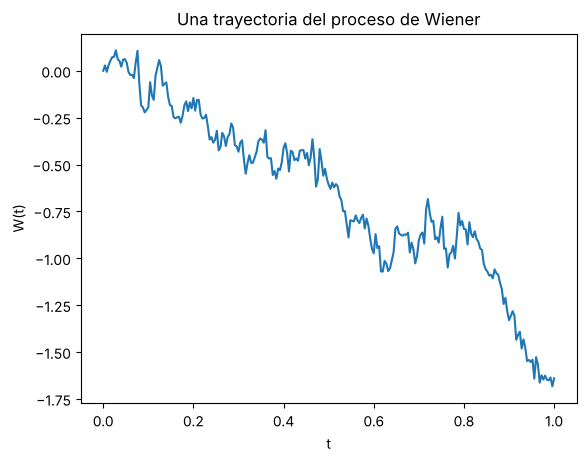

In [17]:
rng = np.random.default_rng(seed=1)
Z = rng.standard_normal(5)          # 5 valores de una normal N(0, 1)
print(Z)

# Una trayectoria del proceso de Wiener: suma acumulada de incrementos sqrt(dt)·Z
n, T = 250, 1.0
dt = T / n
W = np.concatenate([[0.0], np.cumsum(np.sqrt(dt) * rng.standard_normal(n))])
plt.plot(np.linspace(0, T, n + 1), W)
plt.title("Una trayectoria del proceso de Wiener"); plt.xlabel("t"); plt.ylabel("W(t)")
plt.show()

### ✏️ Ejercicio 7
Con `rng = np.random.default_rng(42)`, genera **10 000** valores de una $N(0,1)$ y calcula su media.
Debería estar muy cerca de 0 (diferencia menor que 0.05).

In [18]:
media_normal = None   # ← tu código

if media_normal is not None:
    print("✅ ¡Correcto!" if abs(media_normal) < 0.05 else "❌ Revisa: la media debería estar cerca de 0")
else:
    comprobar(None, 0)

⏳ Aún sin responder: escribe tu código en lugar de None y vuelve a ejecutar la celda.


## 8. Leer un mensaje de error sin pánico

Cuando algo falla, Python muestra un *traceback*. **Lee primero la última línea**: dice el *tipo* de error y
una pista. Luego busca la flecha `---->` que señala la línea de tu código.

| Error | Qué significa normalmente | Qué hacer |
|---|---|---|
| `NameError: name 'x' is not defined` | Usas una variable que no existe (o no ejecutaste su celda) | Ejecuta las celdas anteriores; revisa mayúsculas |
| `SyntaxError` | Falta un paréntesis, dos puntos `:` o comillas | Mira justo antes de donde señala la flecha |
| `IndentationError` | Sangría incorrecta en una función o un `if` | Usa 4 espacios, de forma consistente |
| `TypeError` | Operación con tipos incompatibles (p. ej. texto + número, lista − número) | Convierte con `np.array(...)` o `float(...)` |
| `ValueError: operands could not be broadcast together with shapes ...` | Vectores o matrices de tamaños incompatibles | Imprime `.shape` de cada uno |
| `KeyError: 'S'` | La columna no se llama así en el DataFrame | Imprime `datos.columns` |
| `FileNotFoundError` | El archivo no está en esa ruta | Comprueba la ruta o usa la URL de GitHub |
| `ModuleNotFoundError: No module named ...` | Falta instalar una librería | En Colab: `!pip install nombre` |

Ejecuta la celda siguiente: provoca errores a propósito y muestra el mensaje sin detener el cuaderno.

In [19]:
ejemplos = {
    "NameError":  "precio_final * 2",
    "TypeError":  "[1, 2, 3] - 1",
    "ValueError": "np.array([1, 2, 3]) + np.array([1, 2])",
    "KeyError":   "datos['Precio']",
}
for tipo, instruccion in ejemplos.items():
    try:
        eval(instruccion)
    except Exception as e:
        print(f"{instruccion:42s} → {type(e).__name__}: {e}")

precio_final * 2                           → NameError: name 'precio_final' is not defined
[1, 2, 3] - 1                              → TypeError: unsupported operand type(s) for -: 'list' and 'int'
np.array([1, 2, 3]) + np.array([1, 2])     → ValueError: operands could not be broadcast together with shapes (3,) (2,) 
datos['Precio']                            → KeyError: 'Precio'


## 9. ¿Listo para el curso?

- [ ] Ejecuto celdas, reinicio el cuaderno y entiendo por qué importa el orden.
- [ ] Uso `np.exp`, `np.log`, `np.maximum`, `np.linspace` sobre arrays.
- [ ] Escribo una función con `def ... return`.
- [ ] Hago una gráfica con título, ejes, línea del cero y un punto marcado.
- [ ] Leo un CSV y calculo rendimientos con `shift`.
- [ ] Multiplico matrices con `@` y calculo una matriz de covarianzas.
- [ ] Leo la última línea de un error antes de pedir ayuda.

Si marcaste todo, abre el [cuaderno de la Clase 1](../semana-01/). Si algo no quedó claro, consulta la
[Guía para principiantes](../../docs/guia-principiantes.md) o plantea tu duda en el foro «Pregúntale a tu profesor».

---
## Soluciones

Inténtalo primero. Ver la solución antes de pelearte con el ejercicio aprende mucho menos.

In [20]:
# Ejercicio 1
valor_actual = 100 * np.exp(-0.05 * 2)
comprobar(valor_actual, 90.48374180359595)

# Ejercicio 2
pago_put = np.maximum(100 - ST2, 0)
comprobar(pago_put, [20, 0, 0])

# Ejercicio 3
def bp_put_larga(ST, K, P):
    return np.maximum(K - ST, 0) - P
comprobar(bp_put_larga(np.array([80, 100, 120]), K=100, P=4), [16, -4, -4])

# Ejercicio 5
media_simple = (S / S.shift(1) - 1).dropna().mean()
comprobar(media_simple, 0.0028407083711, tol=1e-10)

# Ejercicio 6
C = np.cov(R, rowvar=False)
comprobar(C, [[0.000241666667, 0.00007], [0.00007, 0.0000346666667]], tol=1e-10)

# Ejercicio 7
media_normal = np.random.default_rng(42).standard_normal(10_000).mean()
print(f"media = {media_normal:.4f}")

✅ ¡Correcto!
✅ ¡Correcto!
✅ ¡Correcto!
✅ ¡Correcto!
✅ ¡Correcto!
media = -0.0102


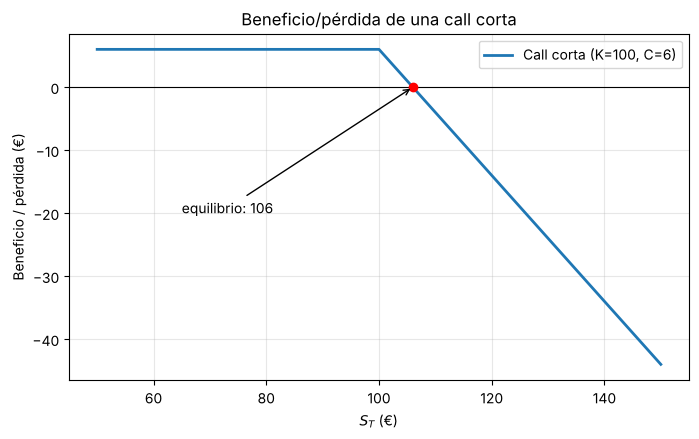

In [21]:
# Ejercicio 4
ST = np.linspace(50, 150, 201)
K, C_prima = 100, 6
bp_corta = C_prima - np.maximum(ST - K, 0)

plt.figure(figsize=(8, 4.5))
plt.plot(ST, bp_corta, linewidth=2, label=f"Call corta (K={K}, C={C_prima})")
plt.axhline(0, color="black", linewidth=0.8)
plt.plot(K + C_prima, 0, "o", color="red")
plt.annotate(f"equilibrio: {K + C_prima}", (K + C_prima, 0), xytext=(65, -20),
             arrowprops=dict(arrowstyle="->"))
plt.xlabel("$S_T$ (€)"); plt.ylabel("Beneficio / pérdida (€)")
plt.title("Beneficio/pérdida de una call corta"); plt.grid(alpha=0.3); plt.legend()
plt.show()